# Práctica 2.2 — k vecinos más cercanos: dime con quién andas

Este cuaderno acompaña la clase «k vecinos más cercanos» (kNN, por *k-nearest neighbors*) y usa **los mismos hogares** de las prácticas de árbol de decisión y random forest, para comparar los modelos. Sigue el recorrido de la clase:

1. Datos y partición · 2. **¿Por qué escalar?** · 3. Los vecinos de un hogar · 4. **Mapas de decisión** según k · 5. **Elegir k** con validación cruzada · 6. ¿Más variables es mejor? · 7. **Métricas**: línea base, logística, árbol y kNN · 8. Curvas ROC · 9. Entrenamiento frente a prueba

**Datos.** `datos/2-2-hogares-subsidio.xlsx`: 1.200 hogares **simulados con fines didácticos**; la variable objetivo es **pobre (Sí/No)**.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 1. Datos y partición

La misma preparación, semilla y partición estratificada 75/25 de las prácticas del árbol y del bosque. Además se separan las dos variables del plano de la clase: el ingreso por persona y la educación de quien encabeza el hogar.

In [3]:
hog = pd.read_excel(DATOS / '2-2-hogares-subsidio.xlsx', sheet_name='hogares')
hog['es_pobre'] = (hog['pobre'] == 'Sí').astype(int)
def preparar(d):
    X = d[['personas', 'menores_5', 'adultos_mayores', 'educacion_jefe', 'ocupados', 'ingreso_pc', 'cuartos', 'hacinamiento']].copy()
    for c in ['jefe_mujer', 'acueducto', 'piso_tierra', 'internet']:
        X[c] = (d[c] == 'Sí').astype(int)
    X['rural'] = (d['zona'] == 'Rural').astype(int)
    return X.join(pd.get_dummies(d[['tipo_municipio', 'regimen_salud']], dtype=int)).astype(float)
X, y = preparar(hog), hog['es_pobre']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEMILLA, stratify=y)
print(f'{len(hog)} hogares, {y.mean():.1%} pobres · entrenamiento {len(Xtr)} · prueba {len(Xte)} · {X.shape[1]} variables')
X2tr, X2te = Xtr[['ingreso_pc', 'educacion_jefe']], Xte[['ingreso_pc', 'educacion_jefe']]   # las dos variables del plano

def metricas(yv, p, u=0.5):
    h = (p >= u).astype(int)
    return {'exactitud': accuracy_score(yv, h), 'precisión': precision_score(yv, h, zero_division=0), 'sensibilidad': recall_score(yv, h),
            'F1': f1_score(yv, h), 'AUC': roc_auc_score(yv, p) if np.std(p) > 0 else 0.5}
def matriz(ax, yv, p, titulo, u=0.5):
    m = confusion_matrix(yv, (p >= u).astype(int))
    ax.imshow([[0, 1], [1, 0]], cmap=LinearSegmentedColormap.from_list('mc', ['#e8f2fc', '#fbe3e3']), vmin=0, vmax=1)
    for (i, j), r in zip([(0, 0), (0, 1), (1, 0), (1, 1)], ['VN', 'FP', 'FN', 'VP']):
        ax.text(j, i, f'{r}\n{m[i, j]}', ha='center', va='center', fontsize=15, color=TINTA)
    ax.set_xticks([0, 1], ['no pobre', 'pobre']); ax.set_yticks([0, 1], ['no pobre', 'pobre'])
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); ax.set_title(titulo); ax.grid(False)

# rejilla del plano ingreso × educación (ingreso hasta 1,5 millones de pesos por persona)
gi, ge = np.meshgrid(np.linspace(0, 1_500_000, 160), np.linspace(0, 20, 120))
rejilla = pd.DataFrame({'ingreso_pc': gi.ravel(), 'educacion_jefe': ge.ravel()})
def dibujar_mapa(ax, modelo, titulo, puntos=True):
    p = modelo.predict_proba(rejilla)[:, 1].reshape(gi.shape)
    ax.contourf(gi / 1000, ge, p, levels=np.linspace(0, 1, 11), cmap=DIV, alpha=.55)
    ax.contour(gi / 1000, ge, p, levels=[.5], colors=TINTA, linewidths=1.5)
    if puntos:
        v = X2tr[X2tr['ingreso_pc'] <= 1_500_000].iloc[:250]
        ax.scatter(v['ingreso_pc'] / 1000, v['educacion_jefe'] + rng_j.uniform(-.3, .3, len(v)), s=10,
                   c=np.where(ytr.loc[v.index] == 1, NARANJA, AZUL), edgecolor='white', lw=.4)
    ax.set_xlim(0, 1500); ax.set_ylim(0, 20); ax.set_title(titulo)
    ax.set_xlabel('Ingreso por persona (miles de pesos)'); ax.set_ylabel('Años de educación del jefe')
rng_j = np.random.default_rng(SEMILLA)

1200 hogares, 32.8% pobres · entrenamiento 900 · prueba 300 · 19 variables


Es la misma base de las prácticas del árbol y del bosque: **1.200 hogares, el 32,8 % pobres**, con 900 para entrenar y 300 para la prueba, y las mismas 19 variables. Como la semilla y la partición son idénticas, las cifras de kNN se pueden comparar directamente con las de los otros modelos. También quedan listas la función `metricas`, la de la matriz de confusión y la rejilla para pintar mapas de decisión.

## 2. ¿Por qué escalar?

kNN decide con **distancias**: la línea recta entre dos hogares en el espacio de las variables. Si una variable se mide en números mucho más grandes que otra, domina la distancia. Aquí el ingreso está en **pesos** y la educación en **años**.

In [4]:
print(X2tr.describe().loc[['mean', 'std', 'min', 'max']])
a, b = X2tr.iloc[0], X2tr.iloc[1]
d_ing, d_edu = a['ingreso_pc'] - b['ingreso_pc'], a['educacion_jefe'] - b['educacion_jefe']
print(f'\nDos hogares: diferencia de ingreso {d_ing:,.0f} pesos y de educación {d_edu:.0f} años')
print(f'En la distancia al cuadrado, el ingreso aporta {d_ing**2:,.0f} y la educación {d_edu**2:.0f}')
esc = StandardScaler().fit(X2tr)
za, zb = esc.transform(X2tr.iloc[[0, 1]])
print(f'Con las variables escaladas: diferencia {za[0] - zb[0]:.2f} desviaciones en ingreso y {za[1] - zb[1]:.2f} en educación')

sin = KNeighborsClassifier(n_neighbors=9).fit(X2tr, ytr)
con = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)).fit(X2tr, ytr)
for nombre, m in [('sin escalar', sin), ('escaladas', con)]:
    print(f'kNN (k = 9, 2 variables) {nombre:12s}: exactitud en prueba {accuracy_score(yte, m.predict(X2te)):.3f} · AUC {roc_auc_score(yte, m.predict_proba(X2te)[:, 1]):.3f}')

        ingreso_pc  educacion_jefe
mean   892,716.667           8.888
std  1,039,941.088           3.743
min     33,000.000           0.000
max  9,792,000.000          19.000

Dos hogares: diferencia de ingreso 826,000 pesos y de educación 3 años
En la distancia al cuadrado, el ingreso aporta 682,276,000,000 y la educación 9
Con las variables escaladas: diferencia 0.79 desviaciones en ingreso y 0.80 en educación
kNN (k = 9, 2 variables) sin escalar : exactitud en prueba 0.847 · AUC 0.891
kNN (k = 9, 2 variables) escaladas   : exactitud en prueba 0.907 · AUC 0.936


El ingreso por persona tiene una desviación estándar de **1.039.941 pesos**; la educación, de **3,7 años**. Entre los dos primeros hogares hay 826.000 pesos y 3 años de diferencia. En la distancia al cuadrado, el ingreso aporta 682.276.000.000 y la educación **9**: la educación no cuenta para nada.

Al escalar (restar la media y dividir por la desviación del entrenamiento), las dos diferencias quedan comparables: **0,79 desviaciones en ingreso y 0,80 en educación**. El efecto sobre el modelo es claro, con k = 9 y las dos variables:

- **Sin escalar:** exactitud en prueba 0,847 y AUC 0,891.
- **Con las variables escaladas:** exactitud **0,907** y AUC **0,936**.

En kNN escalar no es un detalle técnico: cambia quiénes son los vecinos. Por eso el escalador va dentro de un `Pipeline`, que lo ajusta solo con el entrenamiento.

## 3. Los vecinos de un hogar

kNN no aprende parámetros: **guarda el entrenamiento**. Para un hogar nuevo, mide su distancia a todos, se queda con los *k* más cercanos y cuenta cuántos son pobres. Esa proporción es la probabilidad.

In [5]:
i = next(i for i in range(len(X2te)) if 0.3 <= con.predict_proba(X2te.iloc[[i]])[0, 1] <= 0.7)   # un hogar con votos divididos
nuevo = X2te.iloc[[i]]
dist, idx = con[-1].kneighbors(con[0].transform(nuevo), n_neighbors=9)
vec = X2tr.iloc[idx[0]].assign(pobre=ytr.iloc[idx[0]].map({1: 'Sí', 0: 'No'}).values, distancia=dist[0])
print(f"Hogar nuevo: ingreso {nuevo['ingreso_pc'].iloc[0]:,.0f} pesos, educación {nuevo['educacion_jefe'].iloc[0]:.0f} años · ¿pobre en realidad? {'Sí' if yte.iloc[i] else 'No'}")
print(f'Probabilidad = {(vec.pobre == "Sí").sum()} pobres de 9 = {con.predict_proba(nuevo)[0, 1]:.3f}')
vec

Hogar nuevo: ingreso 476,000 pesos, educación 6 años · ¿pobre en realidad? Sí
Probabilidad = 6 pobres de 9 = 0.667


,ingreso_pc,educacion_jefe,pobre,distancia
274,"475,000.000",6.000,Sí,0.001
873,"492,000.000",6.000,No,0.015
785,"457,000.000",6.000,Sí,0.018
564,"455,000.000",6.000,Sí,0.020
200,"502,000.000",6.000,Sí,0.025
50,"448,000.000",6.000,No,0.027
867,"511,000.000",6.000,Sí,0.034
104,"520,000.000",6.000,No,0.042
577,"411,000.000",6.000,Sí,0.063


El hogar elegido tiene un ingreso de 476.000 pesos por persona y 6 años de educación del jefe, y en realidad es pobre. Sus 9 vecinos más cercanos tienen todos **6 años de educación** y un ingreso entre 411.000 y 520.000 pesos. Con las variables escaladas, un año de educación pesa más que 100.000 pesos de ingreso, así que los vecinos coinciden primero en la educación.

**6 de los 9 vecinos son pobres**, así que la probabilidad es 6/9 = **0,667**. Con el umbral de 0,5, el hogar se clasifica como pobre, y acierta. No hay ecuación ni coeficientes: la predicción se explica mostrando los vecinos.

## 4. Mapas de decisión según k

Con dos variables se puede pintar el plano: cada punto se colorea según la probabilidad que le daría kNN (naranja, pobre; azul, no pobre) y la línea negra es la frontera de 0,5.

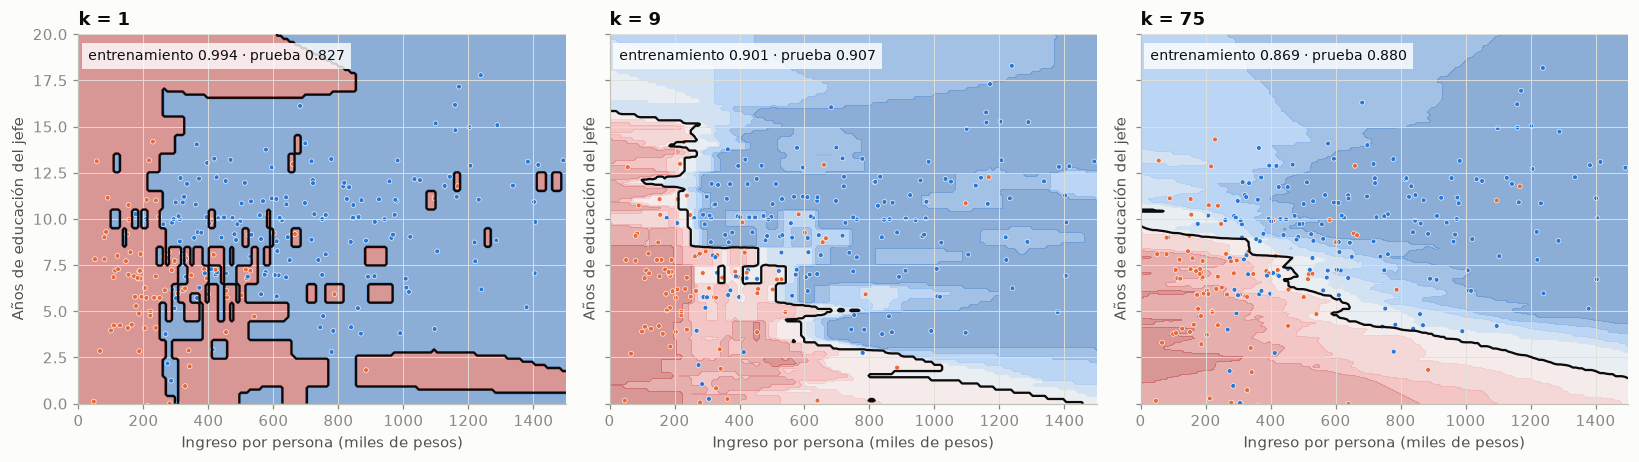

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, k in zip(axs, [1, 9, 75]):
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X2tr, ytr)
    dibujar_mapa(ax, m, f'k = {k}')
    ax.text(30, 18.6, f'entrenamiento {accuracy_score(ytr, m.predict(X2tr)):.3f} · prueba {accuracy_score(yte, m.predict(X2te)):.3f}',
            fontsize=9, color=TINTA, bbox=dict(fc='white', ec='none', alpha=.8))
plt.tight_layout(); plt.show()

Los tres mapas muestran el papel de *k*:

- **k = 1:** la frontera se llena de **islas** alrededor de hogares sueltos. Acierta 0,994 en entrenamiento, pero solo **0,827 en prueba**: memoriza el ruido.
- **k = 9:** la frontera sigue la forma de los datos (pobreza con ingreso bajo, sobre todo con poca educación), casi sin islas. Acierta 0,901 en entrenamiento y **0,907 en prueba**.
- **k = 75:** la frontera se vuelve casi una recta diagonal. Pierde detalle: 0,869 en entrenamiento y 0,880 en prueba.

Pocos vecinos sobreajustan y demasiados subajustan, igual que la profundidad en un árbol.

## 5. Elegir k con validación cruzada

*k* es el hiperparámetro principal. La exactitud en **entrenamiento** engaña: con k = 1 cada hogar es su propio vecino. Por eso se compara con la **validación cruzada** (5 pliegues del entrenamiento) y se elige el mejor *k*, junto con el peso de los vecinos (`uniform`: todos votan igual; `distance`: los más cercanos pesan más).

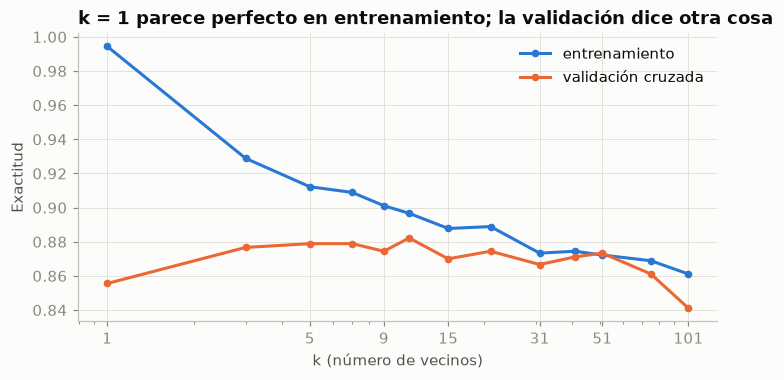

Mejor combinación: {'n_neighbors': 15, 'weights': 'uniform'} · AUC en validación cruzada = 0.933


,1,3,5,7,9,11,15,21,31,41,51,75,101
entrenamiento,0.994,0.929,0.912,0.909,0.901,0.897,0.888,0.889,0.873,0.874,0.872,0.869,0.861
validación cruzada,0.856,0.877,0.879,0.879,0.874,0.882,0.870,0.874,0.867,0.871,0.873,0.861,0.841


In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 75, 101]
curva = pd.DataFrame({'entrenamiento': [accuracy_score(ytr, make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X2tr, ytr).predict(X2tr)) for k in ks],
                      'validación cruzada': [cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)), X2tr, ytr, cv=cv).mean() for k in ks]}, index=ks)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(curva.index, curva['entrenamiento'], color=AZUL, marker='o', ms=4, label='entrenamiento')
ax.plot(curva.index, curva['validación cruzada'], color=NARANJA, marker='o', ms=4, label='validación cruzada')
ax.set_xscale('log'); ax.set_xticks(ks[::2], [str(k) for k in ks[::2]]); ax.set_xlabel('k (número de vecinos)'); ax.set_ylabel('Exactitud'); ax.legend()
ax.set_title('k = 1 parece perfecto en entrenamiento; la validación dice otra cosa'); plt.show()

busq = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                    {'kneighborsclassifier__n_neighbors': ks, 'kneighborsclassifier__weights': ['uniform', 'distance']}, cv=cv, scoring='roc_auc').fit(X2tr, ytr)
print('Mejor combinación:', {k.split('__')[1]: v for k, v in busq.best_params_.items()}, f'· AUC en validación cruzada = {busq.best_score_:.3f}')
curva.T

La curva muestra la trampa del entrenamiento: con **k = 1**, la exactitud en entrenamiento es **0,994**, porque cada hogar se encuentra a sí mismo; en validación cruzada es solo **0,856**. Al subir *k*, el entrenamiento baja y la validación sube hasta un máximo de **0,882 con k = 11**, para caer otra vez desde k = 51 (0,841 con k = 101).

La búsqueda con el AUC eligió **k = 15 con votos iguales** (`uniform`), con un AUC de validación de **0,933**. Entre k = 5 y k = 51 la exactitud de validación varía poco (de 0,867 a 0,882): cualquier *k* intermedio funciona. Se usan valores impares para evitar empates entre dos clases.

## 6. ¿Más variables es mejor?

Hasta aquí se usaron dos variables. ¿Qué pasa si se le dan a kNN las 19?

In [8]:
conjuntos = {'2 variables (ingreso y educación)': ['ingreso_pc', 'educacion_jefe'],
             '4 variables (+ hacinamiento y piso de tierra)': ['ingreso_pc', 'educacion_jefe', 'hacinamiento', 'piso_tierra'],
             f'todas las {X.shape[1]} variables': list(X.columns)}
filas = []
for nombre, cols in conjuntos.items():
    g = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()), {'kneighborsclassifier__n_neighbors': ks}, cv=cv, scoring='roc_auc').fit(Xtr[cols], ytr)
    p = g.predict_proba(Xte[cols])[:, 1]
    filas.append({'variables': nombre, 'mejor k': g.best_params_['kneighborsclassifier__n_neighbors'], 'AUC validación': g.best_score_,
                  'exactitud prueba': accuracy_score(yte, (p >= .5).astype(int)), 'AUC prueba': roc_auc_score(yte, p)})
pd.DataFrame(filas).set_index('variables')

,mejor k,AUC validación,exactitud prueba,AUC prueba
variables,,,,
2 variables (ingreso y educación),15,0.933,0.887,0.934
4 variables (+ hacinamiento y piso de tierra),9,0.912,0.877,0.928
todas las 19 variables,101,0.893,0.833,0.908


Más variables **empeoran** a kNN con estos datos:

| Variables | Mejor k | AUC en prueba | Exactitud en prueba |
|---|---|---|---|
| 2 (ingreso y educación) | 15 | **0,934** | **0,887** |
| 4 (+ hacinamiento y piso de tierra) | 9 | 0,928 | 0,877 |
| Las 19 | 101 | 0,908 | 0,833 |

Con muchas variables, todos los hogares quedan lejos de todos, y las variables que aportan poco meten ruido en la distancia: los «vecinos» dejan de parecerse en lo que importa. Con las 19 variables la validación tuvo que irse a k = 101 para promediar ese ruido. Es la **maldición de la dimensión**: kNN funciona mejor con pocas variables bien elegidas (y escaladas).

## 7. Métricas: línea base, logística, árbol y kNN

Se comparan en **prueba**. La logística y el árbol usan todas las variables, con los mismos ajustes de sus prácticas; kNN usa el mejor modelo de la sección 5.

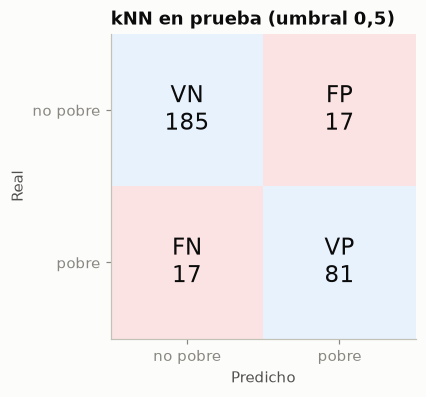

,exactitud,precisión,sensibilidad,F1,AUC
Línea base (nadie es pobre),0.673,0.000,0.000,0.000,0.500
Regresión logística,0.863,0.806,0.765,0.785,0.936
Árbol ajustado,0.917,0.854,0.898,0.876,0.954
kNN (2 variables),0.887,0.827,0.827,0.827,0.934


In [9]:
knn = busq.best_estimator_
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
arbol = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), {'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_leaf': [1, 5, 10, 20]},
                     cv=cv, scoring='roc_auc').fit(Xtr, ytr).best_estimator_
prob = {'Línea base (nadie es pobre)': np.zeros(len(yte)), 'Regresión logística': logit.predict_proba(Xte)[:, 1],
        'Árbol ajustado': arbol.predict_proba(Xte)[:, 1], 'kNN (2 variables)': knn.predict_proba(X2te)[:, 1]}
fig, ax = plt.subplots(figsize=(4, 3.6)); matriz(ax, yte, prob['kNN (2 variables)'], 'kNN en prueba (umbral 0,5)'); plt.show()
pd.DataFrame({k: metricas(yte, p) for k, p in prob.items()}).T

En prueba, frente a la línea base (exactitud 0,673, sin encontrar a ningún hogar pobre):

| Modelo | Exactitud | Sensibilidad | AUC |
|---|---|---|---|
| Regresión logística (19 variables) | 0,863 | 0,765 | 0,936 |
| Árbol ajustado (19 variables) | **0,917** | **0,898** | **0,954** |
| **kNN** (2 variables, k = 15) | 0,887 | 0,827 | 0,934 |

La matriz de kNN: de los 98 hogares pobres de prueba encuentra a **81** y se le escapan **17**; de los 202 no pobres, señala por error a **17**. Por eso su precisión y su sensibilidad son iguales (0,827).

Con solo dos variables, kNN supera en exactitud y sensibilidad a la logística, que usa 19, y la iguala en AUC. El árbol sigue adelante: los datos tienen umbrales e interacciones que el árbol captura con cortes y que kNN solo aproxima con vecinos.

## 8. Curvas ROC

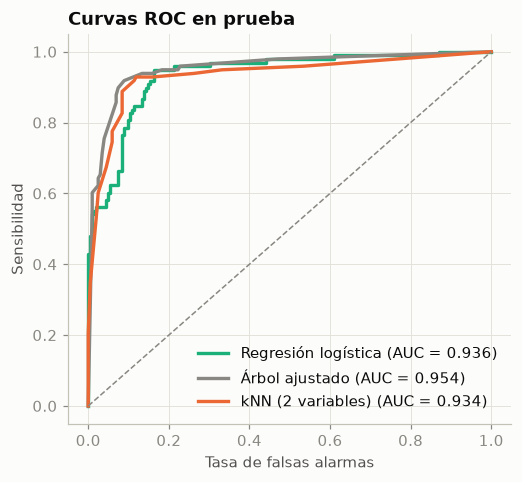

In [10]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for nombre, color in [('Regresión logística', AQUA), ('Árbol ajustado', GRIS), ('kNN (2 variables)', NARANJA)]:
    fpr, tpr, _ = roc_curve(yte, prob[nombre])
    ax.plot(fpr, tpr, color=color, lw=2.2, label=f'{nombre} (AUC = {roc_auc_score(yte, prob[nombre]):.3f})')
ax.plot([0, 1], [0, 1], color=GRIS, ls='--', lw=1)
ax.set_xlabel('Tasa de falsas alarmas'); ax.set_ylabel('Sensibilidad'); ax.set_title('Curvas ROC en prueba'); ax.legend(loc='lower right'); plt.show()

Las tres curvas suben rápido y quedan muy cerca. El árbol (AUC 0,954) va algo por encima; la logística (0,936) y kNN (0,934) casi empatan. La curva de kNN avanza en escalones, porque con k = 15 la probabilidad solo toma 16 valores (0, 1/15, 2/15… 1).

## 9. Entrenamiento frente a prueba

In [11]:
pd.DataFrame({'kNN · entrenamiento': metricas(ytr, knn.predict_proba(X2tr)[:, 1]), 'kNN · prueba': metricas(yte, prob['kNN (2 variables)']),
              'kNN k = 1 · entrenamiento': metricas(ytr, make_pipeline(StandardScaler(), KNeighborsClassifier(1)).fit(X2tr, ytr).predict_proba(X2tr)[:, 1]),
              'kNN k = 1 · prueba': metricas(yte, make_pipeline(StandardScaler(), KNeighborsClassifier(1)).fit(X2tr, ytr).predict_proba(X2te)[:, 1])}).T

,exactitud,precisión,sensibilidad,F1,AUC
kNN · entrenamiento,0.888,0.828,0.831,0.830,0.954
kNN · prueba,0.887,0.827,0.827,0.827,0.934
kNN k = 1 · entrenamiento,0.994,0.993,0.990,0.992,0.993
kNN k = 1 · prueba,0.827,0.730,0.745,0.737,0.806


El kNN elegido casi no pierde de entrenamiento a prueba: exactitud **0,888 y 0,887**, y AUC 0,954 y 0,934. No hay sobreajuste.

Con **k = 1** el contraste es fuerte: exactitud **0,994 en entrenamiento y 0,827 en prueba**, y AUC 0,993 frente a 0,806. Esa brecha es la firma del sobreajuste: el modelo memorizó los hogares de entrenamiento.

## Conclusiones

| Pregunta | Respuesta con estos datos |
|---|---|
| ¿Cómo predice kNN? | Busca los *k* hogares de entrenamiento más parecidos y usa la proporción de pobres entre ellos como probabilidad |
| ¿Hay que escalar? | Sí: sin escalar, el ingreso en pesos aplasta a la educación en años. Con k = 9, la exactitud pasa de 0,847 a 0,907 |
| ¿Cómo influye *k*? | k = 1 memoriza (0,994 en entrenamiento, 0,827 en prueba); k muy grande pierde detalle |
| ¿Qué *k* se eligió? | k = 15 por validación cruzada (AUC 0,933); entre 5 y 51 casi no hay diferencia |
| ¿Más variables es mejor? | No: con las 19 variables el AUC en prueba baja de 0,934 a 0,908 (maldición de la dimensión) |
| ¿Frente a los demás? | AUC en prueba: logística 0,936, **kNN 0,934** (con solo 2 variables), árbol ajustado 0,954 |
| ¿Sobreajusta? | El kNN elegido no: 0,888 en entrenamiento y 0,887 en prueba |

kNN es el modelo más intuitivo: no tiene ecuación, y cada predicción se explica mostrando a los vecinos. A cambio, exige escalar, elegir bien pocas variables y comparar cada hogar nuevo con todos los guardados, lo que lo vuelve lento con muchos datos.

## Retos

1. **Otra forma de escalar.** Cambie `StandardScaler` por `MinMaxScaler` (lleva cada variable a 0–1). ¿Cambian los vecinos del hogar de ejemplo? ¿Y la exactitud?
2. **Votos con peso.** Use `weights='distance'` con k = 15. ¿Qué pasa con la exactitud en entrenamiento? ¿Por qué?
3. **Otra distancia.** Pruebe `metric='manhattan'` (la suma de las diferencias en lugar de la línea recta). ¿Mejora el AUC?
4. **Elegir variables.** Busque la mejor tercera variable para acompañar al ingreso y la educación, probando una por una con validación cruzada. ¿Alguna mejora a las dos solas?
5. **kNN de regresión.** Use `KNeighborsRegressor` para predecir el `ingreso_pc` a partir de la educación, los ocupados y el número de personas, y compare su MAE con el de una regresión lineal.